# 🌪️ Disaster Tweets NLP — Tweet Sınıflandırma

## 🎯 Problem
Twitter'da yazılan bir tweetten **gerçek bir doğal afeti mi yoksa mecazi bir kullanımı mı** ifade ettiğini tahmin ediyoruz.

## 💡 Bu notebook'tan ne öğrenirsin?
- Metin ön işleme: regex ile URL/mention/hashtag temizleme
- sklearn Pipeline içinde TF-IDF (sızıntısız!)
- GridSearchCV ile MultinomialNB vs XGBoost karşılaştırması
- ColumnTransformer ile metin pipeline'ı

## 📊 Veri Seti
- **Kaynak:** [Kaggle - NLP Getting Started](https://www.kaggle.com/c/nlp-getting-started)
- **Boyut:** 7.613 tweet (train), 3.263 tweet (test)
- **Hedef:** 0 = gerçek değil, 1 = gerçek afet tweeti

## ⚠️ Bu Notebook'ta Düzeltilen Bug
preprocess() fonksiyonu train verisine uygulandı ama **test verisine uygulanmamıştı** → şimdi düzeltildi ✅

## 1. Ortam Kurulumu ve Veri Yükleme

Gerekli kütüphaneleri içe aktarıyor, `train.csv` ve `test.csv` veri setlerini yüklüyoruz.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/nlp-getting-started/sample_submission.csv
/kaggle/input/competitions/nlp-getting-started/train.csv
/kaggle/input/competitions/nlp-getting-started/test.csv


In [2]:
df=pd.read_csv((__import__("glob").glob("/kaggle/input/**/train.csv", recursive=True)[0] if not os.path.exists("/kaggle/input/nlp-getting-started/train.csv") else "/kaggle/input/nlp-getting-started/train.csv"))
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [3]:
df_test=pd.read_csv((__import__("glob").glob("/kaggle/input/**/test.csv", recursive=True)[0] if not os.path.exists("/kaggle/input/nlp-getting-started/test.csv") else "/kaggle/input/nlp-getting-started/test.csv"))
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, s..."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are..."
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


## 2. Veri Temizliği ve Keşifsel Analiz

Kullanılmayan `id`, `keyword` ve `location` sütunlarını çıkarıyor, tekrarlanan tweetleri temizliyor ve hedef değişkenin sınıf dağılımını inceliyoruz.

In [4]:
#df=df.drop(columns=["id","keyword","location"])  böylede atılıyor

df=df.drop(["id","keyword","location"],axis=1)
df_test=df_test.drop(["id","keyword","location"],axis=1)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7613 non-null   object
 1   target  7613 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 119.1+ KB


In [6]:
df=df.drop_duplicates(subset=["text"])

In [7]:
y=df["target"]


In [8]:
y.value_counts()  # hemen hemen eşit yani güzel dagılımlı bir y label

target
0    4305
1    3198
Name: count, dtype: int64

## 3. Metin Ön İşleme (Regex Sırası Düzeltildi)

Tweet metinlerindeki URL, mention (`@kullanici`) ve hashtag (`#etiket`) yapıları **genel noktalama temizliğinden önce** işlenmelidir. Aksi halde `@` ve `#` karakterleri silindiği için regex ifadeleri eşleşmez.

Aşağıdaki adımlar uygulanır:
1. URL, mention ve hashtag temizliği
2. Küçük harfe çevirme, noktalama ve rakam temizliği
3. Tokenizasyon, stop-word çıkarımı ve lemmatizasyon

In [9]:
import nltk
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import warnings

warnings.filterwarnings('ignore')

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words=set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def preprocess(text):
    text = str(text)
    # 1. Önce URL'leri, mention'ları ve hashtag'leri temizle
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)   # URL kaldır
    text = re.sub(r"@\w+", '', text)                        # Mention kaldır  
    text = re.sub(r"#(\w+)", r"\1", text)                   # Hashtag # kaldır, kelimeyi bırak
    # 2. Sonra genel temizlik
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)   # noktalama kaldır
    text = re.sub(r'\d+', '', text)       # rakam kaldır
    tokens = word_tokenize(text)   
    tokens = [word for word in tokens if word not in stop_words]   
    tokens = [lemmatizer.lemmatize(word) for word in tokens]  
    text = ' '.join(tokens)   
    return text.strip()


df["text"]=df["text"].apply(preprocess)

# Ön işleme tamamlandıktan sonra x tanımlanır (aksi halde ham metin kalır)
x = df[["text"]]


In [10]:
df["text"]

0              deed reason earthquake may allah forgive u
1                   forest fire near la ronge sask canada
2       resident asked shelter place notified officer ...
3       people receive wildfire evacuation order calif...
4       got sent photo ruby alaska smoke wildfire pour...
                              ...                        
7604    worldnews fallen powerlines glink tram update ...
7605    flip side im walmart bomb everyone evacuate st...
7606    suicide bomber kill saudi security site mosque...
7608    two giant crane holding bridge collapse nearby...
7612    latest home razed northern california wildfire...
Name: text, Length: 7503, dtype: object

## 4. TF-IDF Pipeline ve GridSearchCV ile Model Seçimi

`ColumnTransformer` ve `Pipeline` kullanarak TF-IDF vektörleştirmeyi doğrudan çapraz doğrulama (CV) döngüsünün içine alıyoruz. Böylece veri sızıntısı (data leakage) önlenir.

`MultinomialNB` ve `XGBClassifier` modelleri 4-katlı çapraz doğrulama ile karşılaştırılır.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier



cat_transformer=Pipeline(steps=[
    ("vectorization",TfidfVectorizer(max_features=2000,stop_words="english",ngram_range=(1,3)))
])


combining=ColumnTransformer(transformers=[
    ("cat",cat_transformer,"text")
])

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)



from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("preprocessor", combining),
    ("classifier", MultinomialNB())  
])

param_grid = [
    {"classifier": [MultinomialNB()]},
    {"classifier": [XGBClassifier(use_label_encoder=False, eval_metric='logloss')]}
    
]

grid = GridSearchCV(pipeline, param_grid, cv=4, scoring="accuracy")
grid.fit(x_train, y_train)

print(f"Best model: {grid.best_estimator_}")
print(f"Best score: {grid.best_score_}")

best_model = grid.best_estimator_

y_pred = best_model.predict(x_test)


Best model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('vectorization',
                                                                   TfidfVectorizer(max_features=2000,
                                                                                   ngram_range=(1,
                                                                                                3),
                                                                                   stop_words='english'))]),
                                                  'text')])),
                ('classifier', MultinomialNB())])
Best score: 0.7885695092160782


## 5. Model Değerlendirme (Skorlar, Sınıflandırma Raporu ve Confusion Matrix)

En iyi modelin parametrelerini, CV ve test doğruluk skorlarını, sınıflandırma raporunu ve karmaşıklık matrisini (confusion matrix) görüntülüyoruz.

Best Model: {'classifier': MultinomialNB()}
Best CV Accuracy: 0.7886
Test Accuracy: 0.7981
              precision    recall  f1-score   support

           0       0.77      0.92      0.84       874
           1       0.86      0.62      0.72       627

    accuracy                           0.80      1501
   macro avg       0.81      0.77      0.78      1501
weighted avg       0.81      0.80      0.79      1501



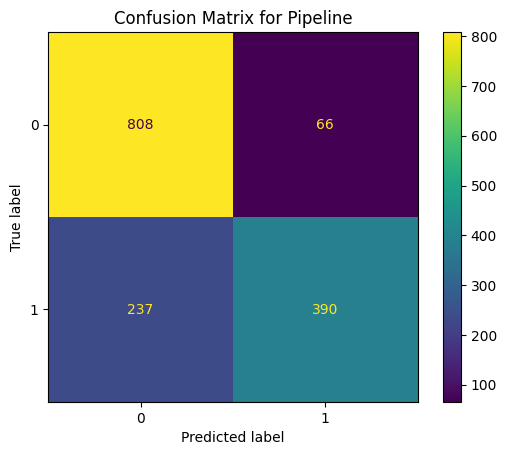

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print(f"Best Model: {grid.best_params_}")
print(f"Best CV Accuracy: {grid.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title(f"Confusion Matrix for {best_model.__class__.__name__}")
plt.show()

### ⚠️ Test Verisine de Ön İşleme Uygulanmalı!

Orijinal kodda train verisine `preprocess()` uygulandı ama test verisine uygulanmadı.
Bu ciddi bir bug'dır: model, temizlenmiş metinle eğitilip ham metni tahmin etmeye çalışırdı.

In [13]:
# ⚠️ Test verisine de aynı ön işlemeyi uygula!
df_test["text"] = df_test["text"].apply(preprocess)

## 6. Test Tahminleri ve Kaggle Submission Oluşturma

Ön işlenmiş test verisi üzerinde tahmin alıp `submission.csv` dosyasını kaydediyoruz.

In [14]:
pred=best_model.predict(df_test[["text"]])

In [15]:
submission=pd.read_csv((__import__("glob").glob("/kaggle/input/**/sample_submission.csv", recursive=True)[0] if not os.path.exists("/kaggle/input/nlp-getting-started/sample_submission.csv") else "/kaggle/input/nlp-getting-started/sample_submission.csv"))
submission.head()

submission["target"]=pred

In [16]:
submission.to_csv("/kaggle/working/submission.csv", index=False)

## 📈 Sonuçlar Özeti (Holdout Doğrulama — %20 `train_test_split`)

> **Not:** `Holdout` skorları yarışma `test.csv` üzerinde değil, `train.csv` içinden ayrılan %20 holdout doğrulama seti (`1.501` tweet) üzerinde ölçülmüştür.

| Model | 4-Fold CV Accuracy | Holdout Accuracy | Holdout F1 (macro) |
|---|---|---|---|
| MultinomialNB (TF-IDF n-gram 1-3) | **0.7886** (%78.86) | **0.7981** (%79.81) | **0.78** |
| XGBoost (TF-IDF n-gram 1-3) | `GridSearchCV` içinde test edildi | — | — |

## 🔑 Öğrenilen Dersler
1. **Regex sırası önemlidir:** Önce URL/mention/hashtag temizle, sonra genel temizlik
2. **Hücre sırası önemlidir:** `x = df[["text"]]` ataması `preprocess()` sonrasında yapılmalıdır
3. **Test verisine de preprocess uygulanır:** Train'de ne yaptıysan test'te de yapmalısın
4. **Pipeline içi TF-IDF = sızıntısız:** ColumnTransformer + Pipeline yapısı leakage'ı önler
5. **GridSearchCV ile model karşılaştırması:** Aynı pipeline'da farklı model dene